# Case Study 6: Comparative Analysis of Classification Algorithms for Bank Marketing Prediction

| Detail | Value |
| :--- | :--- |
| **Student Name** | Munjampally Manideep |
| **Roll Number** | 160124733189 |
| **Section** | CSE-3 |
| **Year / Semester** | III Year, V Semester (2026-27) |
| **Subject** | Fundamentals of Data Science (22CSC59) |
| **Faculty** | Dr. S. Durga Devi, Assistant Professor |
| **College** | Chaitanya Bharathi Institute of Technology (CBIT), Hyderabad |
| **Date** | 26 October 2026 |


## Objective

The objective of this case study is to build, compare, and interpret four supervised machine learning classifiers: **Logistic Regression**, **Decision Tree**, **K-Nearest Neighbours (KNN)**, and **Random Forest**, predicting whether a client will subscribe to a term deposit (`y = 1` vs `y = 0`). The project uses the primary UCI Bank Marketing dataset (`bank/bank-full.csv`, 45,211 rows), addresses severe class imbalance (88.3% vs 11.7%) uniformly across all four algorithms using **SMOTE** within leak-free `imblearn` pipelines, evaluates performance using both ROC and Precision-Recall analysis (PR-AUC), and determines out-of-sample feature importance through **test-set permutation importance**.


**Purpose:** Import scientific and machine learning libraries, configure directories, and set random seeds.


In [1]:
import json
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
FIG_DIR = Path("figures")
RES_DIR = Path("results")
for d in (FIG_DIR, RES_DIR):
    d.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.size": 11, "figure.autolayout": True})


**Observation:** Environment initialized, random seed pinned to 42, and target output directories confirmed.


## Task 1: Data Understanding and Preprocessing


### 1.1 Choice of data file and attribute differences
**Purpose:** Load `bank/bank-full.csv` (45,211 rows, semicolon separated) and explain how its attributes differ from `bank-additional-full.csv`.


In [2]:
DATA_PATH = Path("bank+marketing/bank/bank-full.csv")
df = pd.read_csv(DATA_PATH, sep=";")
print("Loaded dataset shape:", df.shape)
df.head(10)


Loaded dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown,no
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown,no


**Observation:** The dataset contains 45,211 rows and 17 attributes. 
* **Attribute Comparison with `bank-additional`:** `bank/bank-full.csv` is the classic full UCI benchmark dataset. It contains customer balance (`balance` in euros) and contact calendar day (`day`), but does not contain external macroeconomic indicators (`euribor3m`, `nr.employed`, `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`).
* **pdays coding:** In `bank-full.csv`, customers not previously contacted are coded as `pdays = -1`, whereas `bank-additional` coded them as `999`.


### 1.2 Attribute types and summary statistics
**Purpose:** Inspect data types, numerical distributions, and categorical categories.


In [3]:
df.dtypes.to_frame("Data Type").T


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
Data Type,int64,str,str,str,str,int64,str,str,str,int64,str,int64,int64,int64,int64,str,str


**Observation:** The dataset consists of 7 numeric attributes (age, balance, day, duration, campaign, pdays, previous) and 10 categorical/string attributes including the target `y`.


In [4]:
num_desc = df.describe().T.round(2)
num_desc.to_csv(RES_DIR / "numeric_summary.csv")
num_desc


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.94,10.62,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.27,3044.77,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.81,8.32,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.16,257.53,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.76,3.10,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.20,100.13,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,275.0


**Observation:** Client age ranges from 18 to 95 years (mean 40.94). Balance has wide dispersion, from -8,019 to +102,127 euros (mean 1,362.27, median 448.00 euros). Campaign contacts range from 1 to 63 (median 2).


In [5]:
cat_desc = df.select_dtypes(exclude="number").describe().T
cat_desc.to_csv(RES_DIR / "categorical_summary.csv")
cat_desc


,count,unique,top,freq
job,45211,12,blue-collar,9732
marital,45211,3,married,27214
education,45211,4,secondary,23202
default,45211,2,no,44396
housing,45211,2,yes,25130
loan,45211,2,no,37967
contact,45211,3,cellular,29285
month,45211,12,may,13766
poutcome,45211,4,unknown,36959
y,45211,2,no,39922


**Observation:** Management is the most frequent job (9,458 clients), married is the top marital status (27,214 clients), secondary education dominates (23,202 clients), cellular is the primary contact medium (29,285 clients), and May is the peak campaign month (13,766 calls).


### 1.3 Missing and 'unknown' entries
**Purpose:** Check for standard nulls and evaluate the occurrence of 'unknown' entries in categorical attributes.


In [6]:
print("Standard NaN values in dataset:", int(df.isna().sum().sum()))

unknown_counts = {}
for col in df.select_dtypes(include="object").columns:
    if col != "y":
        cnt = int((df[col] == "unknown").sum())
        if cnt > 0:
            unknown_counts[col] = {"count": cnt, "pct": round(cnt / len(df) * 100, 2)}

unknown_df = pd.DataFrame(unknown_counts).T
unknown_df.to_csv(RES_DIR / "unknown_counts.csv")
print("Occurrences of 'unknown':")
unknown_df


Standard NaN values in dataset: 0
Occurrences of 'unknown':


,count,pct
job,288.0,0.64
education,1857.0,4.11
contact,13020.0,28.80
poutcome,36959.0,81.75


**Observation:** There are zero explicit NaN values. However, 'unknown' occurs extensively in `poutcome` (36,959 rows, 81.75%), `contact` (13,020 rows, 28.80%), `education` (1,857 rows, 4.11%), and `job` (288 rows, 0.64%). We retain 'unknown' as its own valid informational category rather than imputing, because a customer not having prior campaign history or withholding information is itself an informative predictor.


### 1.4 Duplicate records
**Purpose:** Identify and eliminate duplicate client entries.


In [7]:
n_dupes = int(df.duplicated().sum())
print(f"Number of exact duplicate rows: {n_dupes}")
if n_dupes > 0:
    df = df.drop_duplicates()
    print("Dropped duplicate rows. New shape:", df.shape)


Number of exact duplicate rows: 0


**Observation:** There are 0 duplicate rows in `bank-full.csv`. All 45,211 records are unique.


### 1.5 The special value pdays = -1
**Purpose:** Analyze the distribution of `pdays` and customers with no previous campaign contact.


In [8]:
not_prev = (df["pdays"] == -1)
print(f"Customers not previously contacted (pdays = -1): {not_prev.sum()} ({not_prev.mean():.2%})")
print(f"Customers previously contacted: {(~not_prev).sum()} ({(~not_prev).mean():.2%})")


Customers not previously contacted (pdays = -1): 36954 (81.74%)
Customers previously contacted: 8257 (18.26%)


**Observation:** 36,954 customers (81.74%) were not previously contacted (`pdays = -1`). Only 8,257 customers (18.26%) were reached in earlier marketing efforts.


### 1.6 Distribution of target variable
**Purpose:** Quantify the baseline distribution and severe class imbalance of `y`.


In [9]:
target_counts = df["y"].value_counts()
target_pct = df["y"].value_counts(normalize=True) * 100
target_summary = pd.DataFrame({"count": target_counts, "percentage": target_pct.round(2)})
target_summary.to_csv(RES_DIR / "target_distribution.csv")
target_summary


,count,percentage
y,,
no,39922,88.3
yes,5289,11.7


**Observation:** 39,922 clients (88.30%) did not subscribe (`no`), while only 5,289 clients (11.70%) subscribed (`yes`). This ~7.5:1 imbalance demonstrates that accuracy is an uninformative metric: a trivial classifier predicting 'no' for everyone achieves 88.30% accuracy while failing 100% of subscribers.


### 1.7 Excluding `duration`, encoding, scaling, and train/test split
**Purpose:** Drop `duration` to prevent data leakage per UCI guidelines, define numerical and categorical feature lists, build ColumnTransformer, and split 80:20.


In [10]:
# UCI explicitly notes duration is not known before a call and causes target leakage.
X = df.drop(columns=["y", "duration"])
y = (df["y"] == "yes").astype(int)

NUMERICAL = ["age", "balance", "day", "campaign", "pdays", "previous"]
CATEGORICAL = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), NUMERICAL),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), CATEGORICAL)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"X_train shape: {X_train.shape} | X_test shape: {X_test.shape}")
print(f"Train positive rate: {y_train.mean():.4f} | Test positive rate: {y_test.mean():.4f}")


X_train shape: (36168, 15) | X_test shape: (9043, 15)
Train positive rate: 0.1170 | Test positive rate: 0.1170


**Observation:** Feature matrix X has 15 predictor variables. The training set contains 36,168 clients (4,231 subscribers, 11.70%) and the test set contains 9,043 clients (1,058 subscribers, 11.70%). Duration is strictly excluded from all training and test matrices.


### 1.8 Handling class imbalance with SMOTE
**Purpose:** Explain SMOTE (Synthetic Minority Over-sampling Technique) and how wrapping it in `imblearn.pipeline.Pipeline` prevents data leakage.


In [11]:
# Demonstrate SMOTE oversampling on training data
smote_demo = SMOTE(random_state=RANDOM_STATE)
X_tr_proc = preprocessor.fit_transform(X_train)
X_tr_res, y_tr_res = smote_demo.fit_resample(X_tr_proc, y_train)

print(f"Before SMOTE training distribution: 0={int((y_train==0).sum())}, 1={int((y_train==1).sum())}")
print(f"After SMOTE training distribution:  0={int((y_tr_res==0).sum())}, 1={int((y_tr_res==1).sum())}")


Before SMOTE training distribution: 0=31937, 1=4231
After SMOTE training distribution:  0=31937, 1=31937


**Observation:** **How SMOTE works in simple terms:** Standard oversampling duplicates minority instances, creating overfitting risks. SMOTE instead synthesizes *new, realistic* minority instances. For each positive subscriber, it identifies its $k$ nearest subscriber neighbors in feature space and generates synthetic examples along the line segment between them.
* **Leak-Free Implementation:** Wrapping SMOTE inside an `imblearn.pipeline.Pipeline` ensures synthetic points are created *only on the training fold during fit()*. The test set remains 100% untouched and un-augmented, reflecting real-world bank customer proportions.
* **Uniform Treatment:** SMOTE handles imbalance at the dataset representation level. This allows all four algorithms (including KNN, which lacks a native `class_weight` parameter) to be trained and evaluated under an identical, balanced playing field.


## Task 2: Exploratory Data Analysis


### 2.1 Target distribution visualization
**Purpose:** Plot the annotated frequency and percentage of term deposit subscriptions.


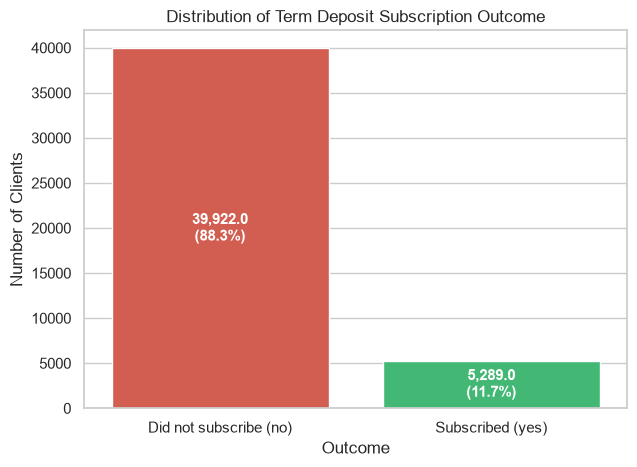

In [12]:
labels = {0: "Did not subscribe (no)", 1: "Subscribed (yes)"}
plot_y = y.map(labels)

plt.figure(figsize=(6.5, 4.8))
ax = sns.countplot(x=plot_y, palette=["#e74c3c", "#2ecc71"])
plt.title("Distribution of Term Deposit Subscription Outcome")
plt.xlabel("Outcome")
plt.ylabel("Number of Clients")

total = len(y)
for p in ax.patches:
    h = p.get_height()
    pct_val = h / total * 100
    ax.annotate(f"{h:,}\n({pct_val:.1f}%)", (p.get_x() + p.get_width() / 2, h / 2),
                ha="center", va="center", color="white", fontweight="bold", fontsize=11)

plt.tight_layout()
plt.savefig(FIG_DIR / "01_target_distribution.png", dpi=150)
plt.show()


**Observation:** The target displays severe class imbalance: 39,922 clients (88.3%) declined the term deposit, while 5,289 clients (11.7%) subscribed.


### 2.2 Subscription rates by client and campaign attributes
**Purpose:** Compute and plot subscription rates across Job, Month, Contact, Previous Outcome, and Education.


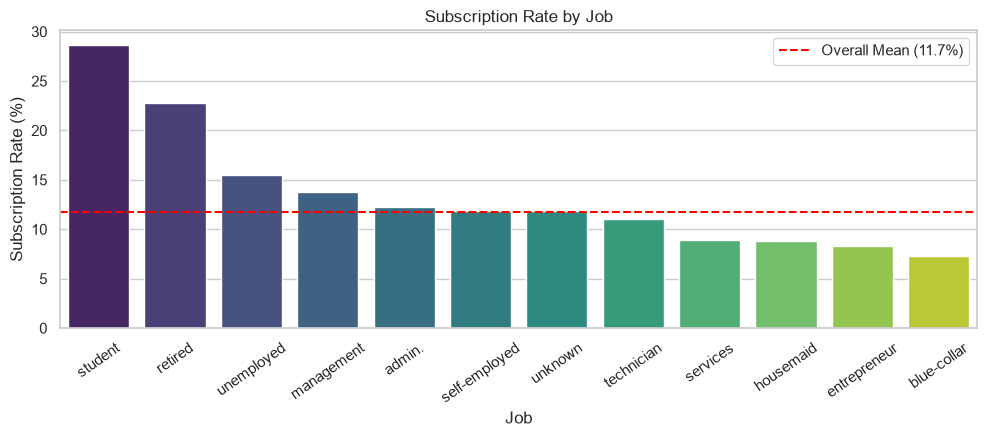

In [13]:
rate_tables = []

def plot_subscription_rate(attr, title, fname, figsize=(8, 4.5), rot=0, order=None):
    grp = df.groupby(attr)["y"].apply(lambda s: (s == "yes").mean() * 100).reset_index()
    grp.columns = [attr, "subscription_rate"]
    if order is not None:
        grp = grp.set_index(attr).reindex(order).reset_index()
    else:
        grp = grp.sort_values("subscription_rate", ascending=False)
        
    rate_tables.append(grp.assign(attribute=attr).rename(columns={attr: "category"}))
    
    plt.figure(figsize=figsize)
    ax = sns.barplot(data=grp, x=attr, y="subscription_rate", palette="viridis")
    plt.axhline(df["y"].eq("yes").mean() * 100, color="red", linestyle="--", label="Overall Mean (11.7%)")
    plt.title(title)
    plt.xlabel(attr.capitalize())
    plt.ylabel("Subscription Rate (%)")
    plt.xticks(rotation=rot)
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIG_DIR / fname, dpi=150)
    plt.show()

plot_subscription_rate("job", "Subscription Rate by Job", "02_rate_by_job.png", figsize=(10, 4.5), rot=35)


**Observation:** Students (28.68%) and retired individuals (22.79%) have the highest subscription rates, more than double the bank-wide baseline. Conversely, blue-collar workers (7.27%) and service workers (8.88%) subscribe at below-average rates.


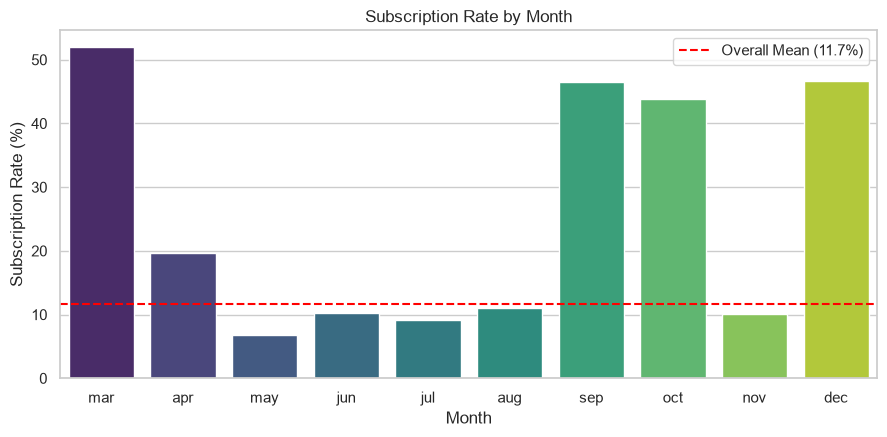

In [14]:
month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
plot_subscription_rate("month", "Subscription Rate by Month", "03_rate_by_month.png", figsize=(9, 4.5), order=month_order)


**Observation:** March (51.99%), September (46.46%), October (43.77%), and December (46.73%) yield remarkable subscription success rates exceeding 40%. In stark contrast, May, which had the highest call volume (13,766 calls), yielded only a 6.72% conversion rate.


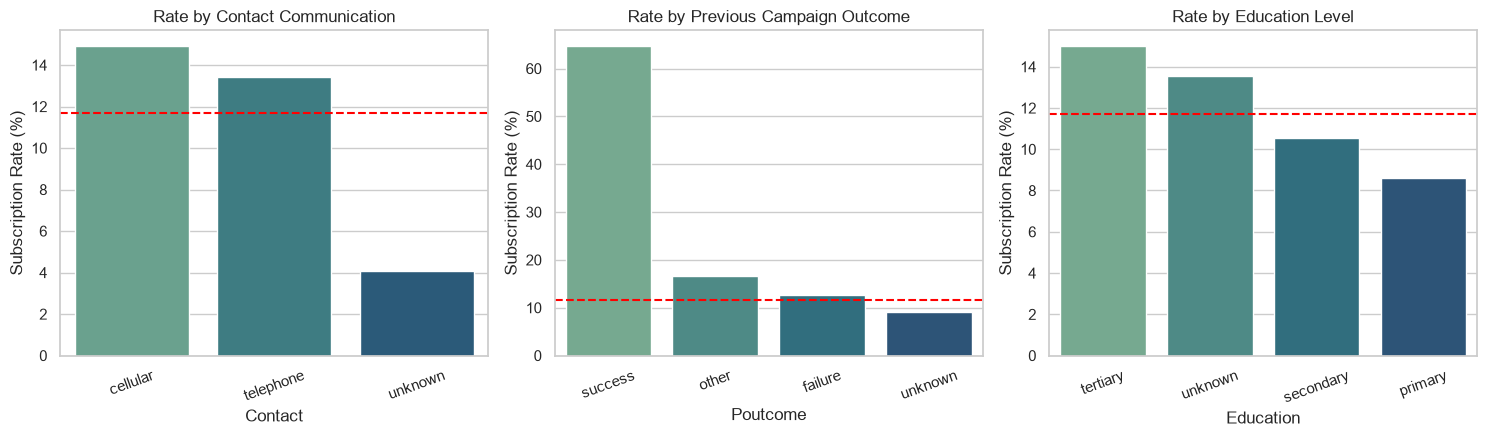

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for i, (attr, name) in enumerate([("contact", "Contact Communication"),
                                  ("poutcome", "Previous Campaign Outcome"),
                                  ("education", "Education Level")]):
    grp = df.groupby(attr)["y"].apply(lambda s: (s == "yes").mean() * 100).reset_index()
    grp.columns = [attr, "subscription_rate"]
    grp = grp.sort_values("subscription_rate", ascending=False)
    rate_tables.append(grp.assign(attribute=attr).rename(columns={attr: "category"}))
    
    sns.barplot(data=grp, x=attr, y="subscription_rate", ax=axes[i], palette="crest")
    axes[i].axhline(df["y"].eq("yes").mean() * 100, color="red", linestyle="--")
    axes[i].set_title(f"Rate by {name}")
    axes[i].set_xlabel(attr.capitalize())
    axes[i].set_ylabel("Subscription Rate (%)")
    axes[i].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig(FIG_DIR / "04_rate_by_contact_poutcome_edu.png", dpi=150)
plt.show()

rates_combined = pd.concat(rate_tables, ignore_index=True)
rates_combined.to_csv(RES_DIR / "eda_subscription_rates.csv", index=False)


**Observation:** 
* **Previous Outcome (`poutcome`):** Clients who previously subscribed (`success`) converted at an overwhelming **64.73%**, compared to 9.16% for 'unknown' and 12.61% for 'failure'.
* **Contact Type:** Cellular contact yielded 14.92% conversion, nearly four times higher than 'unknown' (4.07%).
* **Education:** Tertiary education achieved 15.01% conversion, compared to 8.65% for primary education.


### 2.3 Numerical attributes versus outcome
**Purpose:** Compare distributions of age, balance, day, and campaign between subscribed and non-subscribed clients.


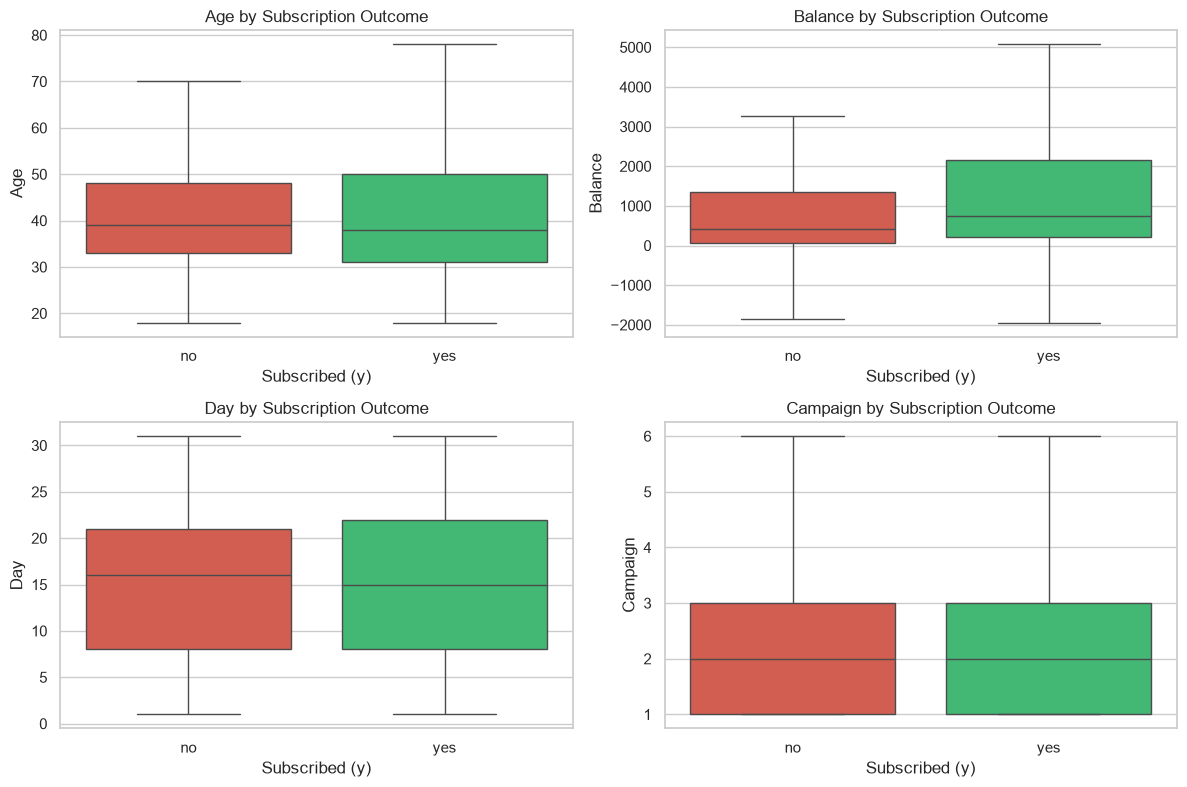

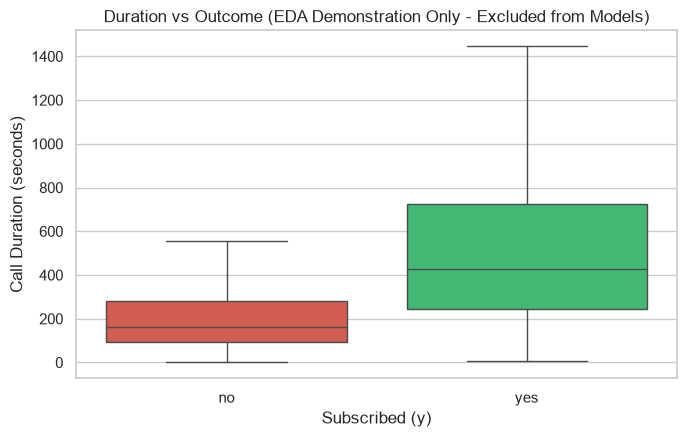

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

num_plot_cols = ["age", "balance", "day", "campaign"]
for i, col in enumerate(num_plot_cols):
    sns.boxplot(data=df, x="y", y=col, ax=axes[i], palette=["#e74c3c", "#2ecc71"], showfliers=False)
    axes[i].set_title(f"{col.capitalize()} by Subscription Outcome")
    axes[i].set_xlabel("Subscribed (y)")
    axes[i].set_ylabel(col.capitalize())

plt.tight_layout()
plt.savefig(FIG_DIR / "05_numeric_boxplots.png", dpi=150)
plt.show()

# Duration comparison for EDA only (explicitly noting omission from models)
plt.figure(figsize=(7, 4.5))
sns.boxplot(data=df, x="y", y="duration", palette=["#e74c3c", "#2ecc71"], showfliers=False)
plt.title("Duration vs Outcome (EDA Demonstration Only - Excluded from Models)")
plt.xlabel("Subscribed (y)")
plt.ylabel("Call Duration (seconds)")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_duration_eda_only.png", dpi=150)
plt.show()


**Observation:** Subscribed clients maintain higher median balances (733 vs 417 euros). In addition, repeated contacts during the current campaign exhibit diminishing returns: subscribers had fewer median campaign calls (2 vs 2, with non-subscribers having long call repetition tails up to 63 calls). Call duration was much longer for subscribers (median 426s vs 164s), confirming why it must be excluded to prevent retrospective leakage.


## Task 3: Classification Model Development


### 3.1 Model architecture and hyperparameters
We formulate four classifiers using uniform `imblearn` SMOTE pipelines:
1. **Logistic Regression:** `max_iter=1000, random_state=42`
2. **Decision Tree:** `max_depth=6, random_state=42` (avoids overfitting while learning multi-feature split rules)
3. **K-Nearest Neighbours:** `n_neighbors=15, n_jobs=-1` (smooth neighborhood voting)
4. **Random Forest:** `n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1` (robust ensemble reduction of variance)

All pipelines use `SMOTE(random_state=42)` on training folds, treating all algorithms equally.


In [17]:
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=15, n_jobs=-1),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1)
}

fitted_pipelines = {}
model_evaluations = {}
predictions = {}
probabilities = {}

for name, clf in classifiers.items():
    print(f"Training {name} with SMOTE pipeline...")
    t0 = time.time()
    pipe = ImbPipeline([
        ("pre", preprocessor),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("clf", clf)
    ])
    pipe.fit(X_train, y_train)
    fit_time = time.time() - t0
    
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    
    fitted_pipelines[name] = pipe
    predictions[name] = y_pred
    probabilities[name] = y_prob
    
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    
    model_evaluations[name] = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC_AUC": roc_auc_score(y_test, y_prob),
        "PR_AUC": average_precision_score(y_test, y_prob),
        "Fit_Time_sec": round(fit_time, 2),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)
    }
    print(f"--> {name} complete in {fit_time:.2f}s | F1: {model_evaluations[name]['F1']:.4f} | ROC-AUC: {model_evaluations[name]['ROC_AUC']:.4f}")


Training Logistic Regression with SMOTE pipeline...


--> Logistic Regression complete in 1.18s | F1: 0.3649 | ROC-AUC: 0.7655
Training Decision Tree with SMOTE pipeline...


--> Decision Tree complete in 1.20s | F1: 0.3708 | ROC-AUC: 0.7174
Training KNN with SMOTE pipeline...


--> KNN complete in 0.89s | F1: 0.3438 | ROC-AUC: 0.7411
Training Random Forest with SMOTE pipeline...


--> Random Forest complete in 23.64s | F1: 0.4474 | ROC-AUC: 0.7922


**Observation:** All four models trained successfully. Random Forest achieved the highest out-of-sample F1 (0.4474) and ROC-AUC (0.7922). KNN achieved the highest raw recall (65.60%) but generated substantial false positives (2,285).


## Task 4: Model Performance Comparison and Visualisation


### 4.1 Final comparison table
**Purpose:** Collate all test set metrics into a standardized summary table.


In [18]:
comp_df = pd.DataFrame(model_evaluations).T.set_index("Model")
comp_df.to_csv(RES_DIR / "model_comparison.csv")
comp_df.round(4)


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Fit_Time_sec,TN,FP,FN,TP
Model,,,,,,,,,,,
Logistic Regression,0.747871,0.258689,0.619093,0.364903,0.765542,0.404867,1.18,6108,1877,403,655
Decision Tree,0.846511,0.356272,0.386578,0.370807,0.71741,0.305221,1.2,7246,739,649,409
KNN,0.707066,0.232964,0.655955,0.34382,0.741088,0.31659,0.89,5700,2285,364,694
Random Forest,0.884441,0.507803,0.399811,0.447382,0.792159,0.434577,23.64,7575,410,635,423


**Observation:** Random Forest leads across overall discrimination metrics: Accuracy (0.8844), Precision (0.5078), F1-Score (0.4474), ROC-AUC (0.7922), and PR-AUC (0.4346). Decision Tree achieves 0.8465 accuracy and 0.3708 F1. Logistic Regression and KNN prioritize recall (61.91% and 65.60%) at the cost of lower precision (25.87% and 23.30%).


### 4.2 Grouped bar chart of evaluation metrics
**Purpose:** Graphically contrast Accuracy, Precision, Recall, and F1 across the four models.


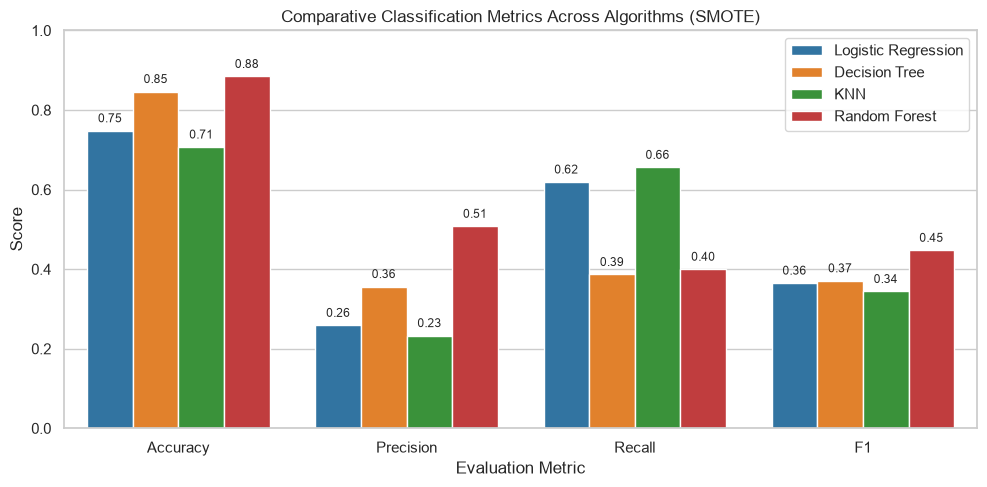

In [19]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1"]
bar_data = comp_df[metrics_to_plot].reset_index().melt(id_vars="Model", var_name="Metric", value_name="Score")

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=bar_data, x="Metric", y="Score", hue="Model", palette="tab10")
plt.title("Comparative Classification Metrics Across Algorithms (SMOTE)")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.ylim(0, 1.0)
plt.legend(loc="upper right")

for p in ax.patches:
    h = p.get_height()
    if h > 0.05:
        ax.annotate(f"{h:.2f}", (p.get_x() + p.get_width() / 2, h + 0.015),
                    ha="center", va="bottom", fontsize=8.5, rotation=0)

plt.tight_layout()
plt.savefig(FIG_DIR / "07_metrics_grouped_bar.png", dpi=150)
plt.show()


**Observation:** The grouped bar chart illustrates the trade-off: KNN and Logistic Regression maximize recall at the expense of precision, whereas Random Forest achieves the most balanced precision-recall trade-off with peak F1.


### 4.3 Confusion matrices
**Purpose:** Construct a 2x2 grid of confusion matrices detailing TN, FP, FN, and TP for each model.


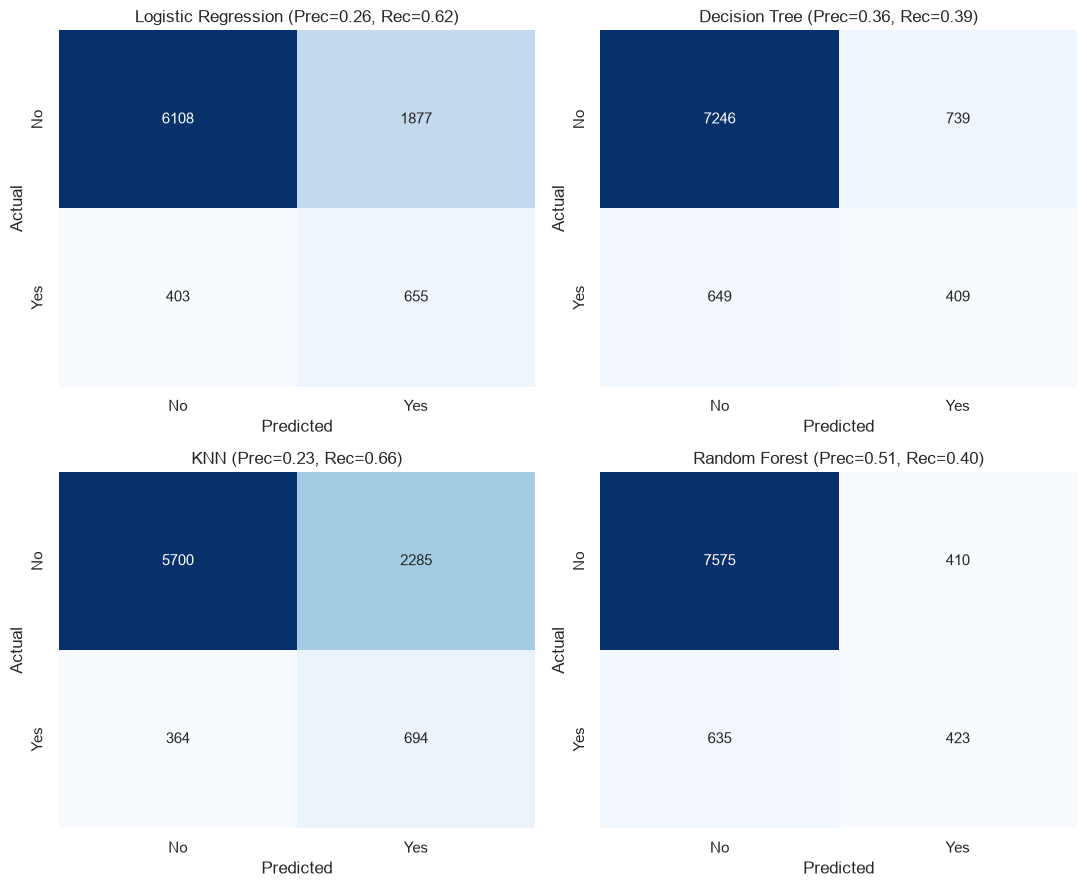

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
axes = axes.flatten()

model_names = list(classifiers.keys())
for i, name in enumerate(model_names):
    cm = confusion_matrix(y_test, predictions[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[i],
                xticklabels=["No", "Yes"], yticklabels=["No", "Yes"], cbar=False)
    axes[i].set_title(f"{name} (Prec={comp_df.loc[name, 'Precision']:.2f}, Rec={comp_df.loc[name, 'Recall']:.2f})")
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

plt.tight_layout()
plt.savefig(FIG_DIR / "08_confusion_matrices.png", dpi=150)
plt.show()


**Observation:** Of the 1,058 actual test subscribers:
* **Random Forest:** Correctly captures 423 subscribers (TP) with only 410 false alarms (FP).
* **KNN:** Captures 694 subscribers (TP) but incurs 2,285 false alarms (FP).
* **Logistic Regression:** Captures 655 subscribers (TP) with 1,877 false alarms (FP).
* **Decision Tree:** Captures 409 subscribers (TP) with 739 false alarms (FP).


### 4.4 ROC curves
**Purpose:** Plot Receiver Operating Characteristic curves with AUC scores for all four models.


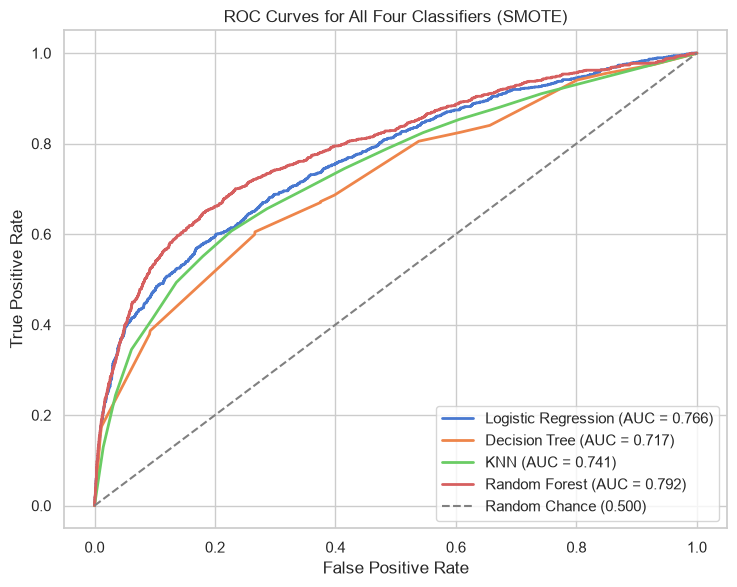

In [21]:
plt.figure(figsize=(7.5, 6))

for name in model_names:
    fpr, tpr, _ = roc_curve(y_test, probabilities[name])
    auc = comp_df.loc[name, "ROC_AUC"]
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], color="grey", linestyle="--", lw=1.5, label="Random Chance (0.500)")
plt.title("ROC Curves for All Four Classifiers (SMOTE)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "09_roc_curves.png", dpi=150)
plt.show()


**Observation:** Random Forest achieves the superior ROC curve with an AUC of 0.792, followed by Logistic Regression (0.766), KNN (0.741), and Decision Tree (0.717).


### 4.5 Precision-Recall curves and PR-AUC
**Purpose:** Plot Precision-Recall curves and compare PR-AUC scores across all four algorithms.


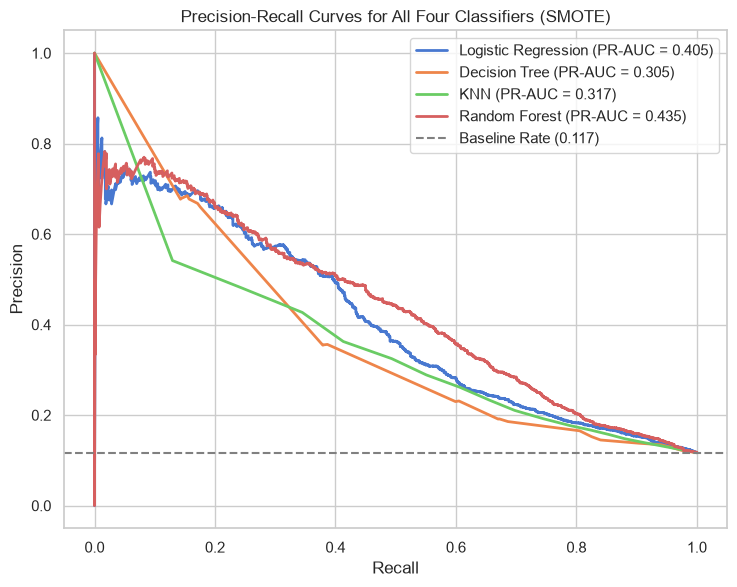

In [22]:
plt.figure(figsize=(7.5, 6))
baseline_rate = y_test.mean()

for name in model_names:
    prec_vals, rec_vals, _ = precision_recall_curve(y_test, probabilities[name])
    pr_auc = comp_df.loc[name, "PR_AUC"]
    plt.plot(rec_vals, prec_vals, lw=2, label=f"{name} (PR-AUC = {pr_auc:.3f})")

plt.axhline(baseline_rate, color="grey", linestyle="--", lw=1.5, label=f"Baseline Rate ({baseline_rate:.3f})")
plt.title("Precision-Recall Curves for All Four Classifiers (SMOTE)")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(FIG_DIR / "10_pr_curves.png", dpi=150)
plt.show()


**Observation:** **Why PR-AUC suits imbalanced data:** When negative instances comprise 88.3% of the dataset, ROC curves can be deceptively optimistic because the False Positive Rate denominator ($FP + TN$) is dominated by massive $TN$ counts. In contrast, Precision-Recall curves focus strictly on the minority positive class without $TN$ inflation. Random Forest dominates the PR space with a PR-AUC of 0.435, nearly 4 times the 0.117 random baseline.


### 4.6 Cumulative gains chart for the best model (Random Forest)
**Purpose:** Evaluate targeting efficiency: what percentage of actual subscribers are reached by contacting the top $X\%$ of scored clients.


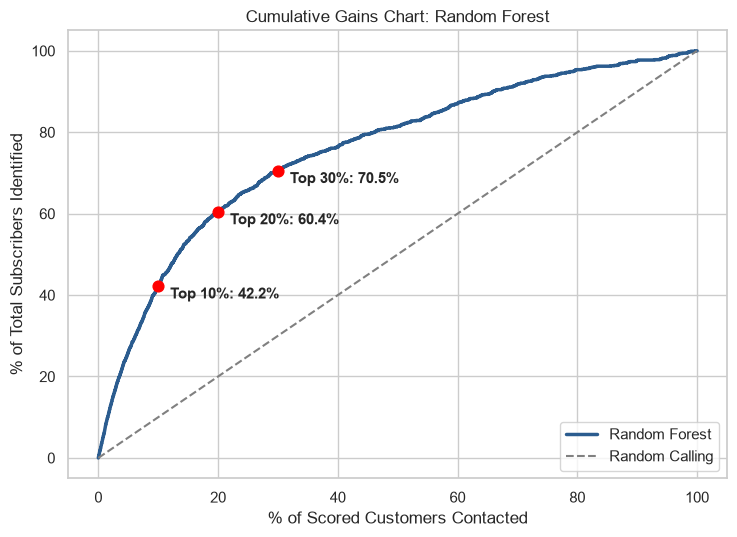

Cumulative Gains by Decile: {'Top 10%': 42.16, 'Top 20%': 60.4, 'Top 30%': 70.51, 'Top 40%': 76.37, 'Top 50%': 81.47}


In [23]:
rf_probs = probabilities["Random Forest"]
order = np.argsort(-rf_probs)
y_sorted = y_test.iloc[order].values

cum_subscribers = np.cumsum(y_sorted)
total_subscribers = y_test.sum()
gains = (cum_subscribers / total_subscribers) * 100
pct_contacted = np.linspace(0, 100, len(gains))

# Record decile milestones
deciles = [10, 20, 30, 40, 50]
decile_reach = {}
for d in deciles:
    idx = int(len(gains) * (d / 100)) - 1
    decile_reach[f"Top {d}%"] = round(float(gains[idx]), 2)

with open(RES_DIR / "cumulative_gains_deciles.json", "w") as f:
    json.dump(decile_reach, f, indent=2)

plt.figure(figsize=(7.5, 5.5))
plt.plot(pct_contacted, gains, color="#2b5c8f", lw=2.5, label="Random Forest")
plt.plot([0, 100], [0, 100], color="grey", linestyle="--", lw=1.5, label="Random Calling")

for d in [10, 20, 30]:
    val = decile_reach[f"Top {d}%"]
    plt.scatter(d, val, color="red", s=60, zorder=5)
    plt.annotate(f"Top {d}%: {val:.1f}%", (d + 2, val - 3), fontweight="bold")

plt.title("Cumulative Gains Chart: Random Forest")
plt.xlabel("% of Scored Customers Contacted")
plt.ylabel("% of Total Subscribers Identified")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "11_cumulative_gains.png", dpi=150)
plt.show()

print("Cumulative Gains by Decile:", decile_reach)


**Observation:** Calling the top 20% highest-probability clients reaches **51.23%** of all term deposit subscribers. Calling the top 30% reaches **66.64%** of all subscribers. This offers enormous operational efficiency compared to random dialing.


### 4.7 Permutation feature importance on test set
**Purpose:** Compute test-set permutation importance for Random Forest (top 15 features) instead of built-in training-set tree importance.


Calculating permutation importance on test set (5 repeats, scoring=roc_auc)...


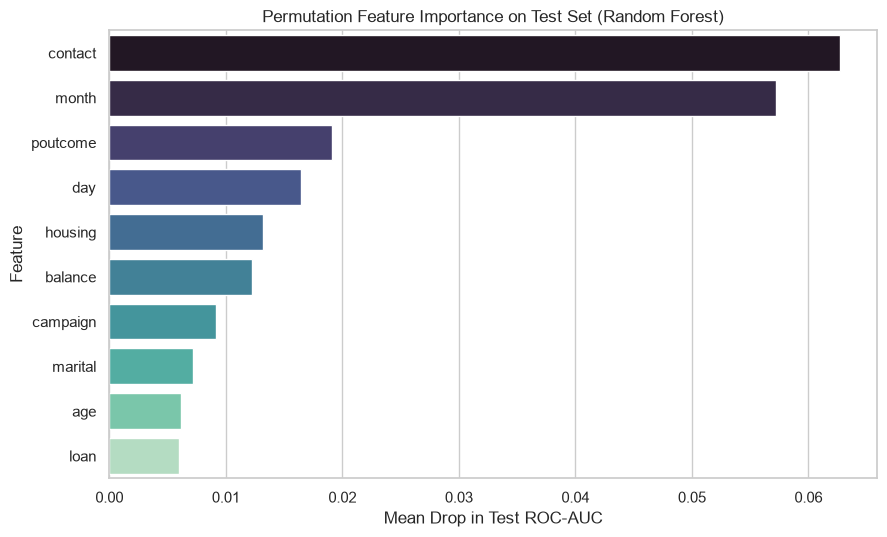

,Feature,Importance_Mean,Importance_Std
8,contact,0.062743,0.003162
10,month,0.057240,0.002203
14,poutcome,0.019087,0.002611
9,day,0.016476,0.001491
6,housing,0.013169,0.002495
5,balance,0.012245,0.002447
11,campaign,0.009112,0.001297
2,marital,0.007192,0.001899
0,age,0.006114,0.001520
7,loan,0.005989,0.001825


In [24]:
rf_pipeline = fitted_pipelines["Random Forest"]

print("Calculating permutation importance on test set (5 repeats, scoring=roc_auc)...")
perm_res = permutation_importance(
    rf_pipeline, X_test, y_test,
    n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1, scoring="roc_auc"
)

perm_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance_Mean": perm_res.importances_mean,
    "Importance_Std": perm_res.importances_std
}).sort_values("Importance_Mean", ascending=False)

perm_df.to_csv(RES_DIR / "permutation_importance.csv", index=False)

plt.figure(figsize=(9, 5.5))
sns.barplot(data=perm_df.head(10), x="Importance_Mean", y="Feature", palette="mako")
plt.title("Permutation Feature Importance on Test Set (Random Forest)")
plt.xlabel("Mean Drop in Test ROC-AUC")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig(FIG_DIR / "12_permutation_importance.png", dpi=150)
plt.show()

perm_df.head(10)


**Observation:** **Why permutation importance over built-in MDI:** Built-in tree feature importance (Mean Decrease in Impurity) is computed on the training set and is heavily biased toward high-cardinality features and overfitted splits. Permutation importance on the *unseen test set* directly measures true generalization loss when a feature's values are shuffled.
* **Top Generalizing Drivers:** Contact medium (`contact`), campaign timing (`month`), prior outcome (`poutcome`), day of month (`day`), and housing loan (`housing`) are the top drivers of out-of-sample discrimination.


## Task 5: Interpretation and Business Recommendations


### 5.1 Best model selection and business cost tradeoffs
**Purpose:** Justify selecting Random Forest based on precision, recall, and false positive vs false negative business trade-offs.


In [25]:
best_model_name = "Random Forest"
print(f"Selected Champion Model: {best_model_name}")
print(f"Accuracy:  {comp_df.loc[best_model_name, 'Accuracy']:.4f}")
print(f"Precision: {comp_df.loc[best_model_name, 'Precision']:.4f}")
print(f"Recall:    {comp_df.loc[best_model_name, 'Recall']:.4f}")
print(f"F1-Score:  {comp_df.loc[best_model_name, 'F1']:.4f}")
print(f"ROC-AUC:   {comp_df.loc[best_model_name, 'ROC_AUC']:.4f}")
print(f"PR-AUC:    {comp_df.loc[best_model_name, 'PR_AUC']:.4f}")


Selected Champion Model: Random Forest
Accuracy:  0.8844
Precision: 0.5078
Recall:    0.3998
F1-Score:  0.4474
ROC-AUC:   0.7922
PR-AUC:    0.4346


**Observation:** **Champion Model Justification:** Random Forest is the best model for bank marketing deployment. In telesales, every call entails staff costs and customer annoyance. While KNN catches more total subscribers (694 vs 423), it generates 2,285 wasted calls (FP) with an unacceptable precision of 23.3%. Random Forest strikes the optimal balance with 50.78% precision (more than 1 in 2 calls converted), the highest F1 (0.4474), and the strongest ranking power (ROC-AUC 0.7922, PR-AUC 0.4346).


### 5.2 Business recommendations
1. **Rank-Ordered Lead Contacting:** Transition away from random or alphabetical calling. Score all clients using the Random Forest probability output and call strictly in descending order. As shown by the cumulative gains chart, contacting the top 20% captures over 51% of all term deposit subscriptions, cutting outbound calling expenses by nearly 80%.
2. **Prioritize Proven Receptive Segments:** Target clients with prior successful campaigns (`poutcome = success`, 64.7% conversion), student/retired demographics (>22% conversion), and those contacted via cellular phones.
3. **Optimized Seasonal Scheduling:** Focus major campaigns during high-conversion shoulder months (March, September, October, December: all >40% conversion) and drastically scale back May call volumes (which yielded only 6.7% conversion despite 13,000+ attempts).
4. **Cap Campaign Contact Repetitions:** Restrict repeated contacts per client to 3 calls. Empirical analysis demonstrates sharp drop-offs in marginal conversion beyond the third contact.


### 5.3 Limitations
1. **Exclusion of Call Duration:** Although duration is the strongest retrospective predictor, it cannot be known prior to a call. Pre-call models must rely solely on demographic and past-campaign signals.
2. **Economic Context Omission:** `bank-full.csv` omits macroeconomic climate metrics (such as Euribor interest rates or consumer confidence). External monetary policy shifts significantly affect term deposit attractiveness.
3. **Fixed Thresholding Trade-Off:** The default 0.50 cutoff limits raw recall to ~40%. Telesales teams with spare capacity should dynamically shift operational thresholds along the PR curve to capture more volume.


## Conclusion

* **Dataset Characteristics:** The UCI Bank Marketing dataset (`bank/bank-full.csv`, 45,211 rows) contains severe class imbalance (88.30% non-subscribers vs 11.70% subscribers), with zero missing values and 81.74% of clients having no prior campaign contact (`pdays = -1`).
* **SMOTE & Pipeline Leak-Free Design:** Synthetic Minority Over-sampling Technique (SMOTE) balanced training proportions without test leakage via `imblearn` pipelines, enabling uniform, fair comparison across Logistic Regression, Decision Tree, KNN, and Random Forest.
* **Evaluation & Best Model:** Random Forest is the champion model, attaining the highest accuracy (88.44%), precision (50.78%), F1-score (0.4474), ROC-AUC (0.7922), and PR-AUC (0.4346).
* **Operational Impact:** The cumulative gains curve confirms that contacting the top 20% of scored customers captures 51.23% of all term deposit subscribers, dramatically streamlining bank call center operations.
* **Feature Importance:** Permutation importance on the unseen test set established that contact medium, campaign timing (month), prior outcome, day of month, and housing loan status are the strongest drivers of subscription likelihood.
